# First Part - Data Handling

**Important Note**: This was a discovery and analysis of the course. Ce n'était pas planifié d'être publique comme livrable mais ça nous a aidé à comprendre ce qui est un défaut de data ou defaut de modèle/mécanisme.

## 0. Context Hasb Gemini (j'ai vérifié)

Based on the project assignment document, here is a detailed explanation of **Project 04 (Prédiction de faisceau mmWave par fusion multimodale)**:

### 1. What is the Core Problem?

In next-generation 6G wireless systems using millimeter-wave (mmWave) or Terahertz frequencies, base stations use massive antenna arrays to form very narrow beams with high signal gain. However, to maintain a strong connection, the transmitter and receiver must precisely align with the correct beam pair.

* **The traditional challenge:** The standard method uses an "exhaustive sweep" through a codebook of dozens to hundreds of possible beams. This causes high latency and heavy signaling overhead, which fails when users are mobile or densely packed.


* **The proposed solution:** **Sensing-aided beam prediction**. Instead of blindly sweeping through all beams, the system uses out-of-band sensors (cameras, LiDAR, radar) to look at the physical environment and directly predict the optimal beam.



---

### 2. What Data and Modalities Are Used?

The project utilizes **DeepSense 6G**, a large-scale real-world dataset that synchronizes 60 GHz mmWave radio measurements with multiple sensing modalities:

* **Camera:** Provides rich semantic context, though it is sensitive to lighting changes and occlusions.


* **LiDAR:** Reliable at night, but expensive and sensitive to weather conditions.


* **Radar:** Robust against weather, but offers lower spatial resolution.


* **GPS:** Helps track location.



---

### 3. What is the Required Work (Socle Obligatoire)?

To complete the mandatory base of the project, you must go through four main steps:

1. **Data Handling & Synchronization:** Download and preprocess DeepSense 6G scenarios, time-align the different sensor streams (which have different sampling rates), and extract the optimal beam labels from received signal strength (RSS) measurements.


2. **Mono-modal Baseline:** Build a single-modality baseline using camera images with a standard Convolutional Neural Network (CNN) like ResNet or MobileNet to predict the optimal beam index out of a 64-beam codebook.


3. **Multimodal Fusion:** Combine at least two modalities (e.g., camera and LiDAR/radar) using feature concatenation or late score fusion.


4. **Evaluation:** Systematically evaluate your models against the traditional exhaustive search baseline. You must quantify the performance in terms of Top-1/Top-3/Top-5 accuracy and measure how many beam tests (and signaling latency) are saved while achieving equivalent accuracy.



---

### 4. What are the Optional Extensions (Bonus)?

If you want to push the project further for extra points, you can tackle:

* **Robustness & Missing Sensors:** Test the multimodal model's resilience when a sensor fails or degrades (e.g., camera occlusions or noisy LiDAR) by training with random modality masking or missing-input-tolerant architectures.


* **Link Blockage Prediction:** Expand the pipeline to predict physical link blockages using the same multimodal sensor data.

---

### 1. Which Scenario(s) to Pick for Kaggle & Publication?

* **The Gold Standard Choice:** **Scenario 33** (Multimodal V2I Dataset).
* **Why it’s publishable:** It is the most comprehensive and heavily cited scenario in recent literature (including 2026 ISAC studies). It natively synchronizes mmWave, camera, LiDAR, radar, and GPS data.
* **The Day-to-Night Angle (Novelty for a Paper):** Scenario 33 captures nighttime vehicle-to-infrastructure (V2I) communication, while Scenarios 31 and 32 cover daytime. A great angle for a publishable paper is testing **cross-domain generalization**—training your multimodal model on daylight scenarios and testing its zero-shot or fine-tuned robustness on Scenario 33 (nighttime), where cameras struggle due to lighting but LiDAR/radar maintain performance.


* **Kaggle Feasibility:** You can download *just* Scenario 33 (or Scenarios 1 and 3) as a standalone zip/folder. They fit comfortably within Kaggle’s storage and working memory limits if you use pre-processed subset `.csv` and image files.

---

### 2. The Publishable Paper Benchmark to Target

To write a strong paper or thesis report, do not just build a model and show accuracy charts. Structure your experiments around a **systematic ablation and generalization study**:

1. **Baseline 1 (Traditional):** Exhaustive Beam Sweep (64 beams) $\rightarrow$ 100% Top-$K$ accuracy, but maximum overhead/latency.


2. **Baseline 2 (Single-Modality):** Camera-only CNN (e.g., ResNet-18). Shows how vision performs and where it fails (e.g., glare, dark conditions).


3. **Proposed Model (Multimodal Fusion):** Camera + LiDAR or Camera + Radar fusion (e.g., late or intermediate feature concatenation).


4. **The "Paper Research Question" (Extension/Bonus Integration):**
* Test **Robustness under Sensor Degradation**. Intentionally drop or mask a modality during testing (simulate a camera occlusion or noisy LiDAR) to prove that your multimodal fusion model degrades gracefully compared to single-modality models.



DeepSense 6G organizes its multi-modal data streams around a master index file (`scenario33_dev.csv`), which acts as the temporal glue synchronizing everything.

---

### 1. The Master Index (`scenario33_dev.csv`)

Each row in this CSV represents a single synchronized snapshot in time. Let us break down what each column category represents:

* **File Path Pointers (`unit1_rgb`, `unit1_pwr_60ghz`, `unit1_lidar`, `unit1_radar`, `unit1_loc`, `unit2_loc`):** These columns contain relative file paths pointing directly to the exact sensor file saved for that specific timestamp index.
* **The Ground Truth Labels (`unit1_beam` and `unit1_max_pwr`):**
* `unit1_beam`: This is an integer representing the **optimal beam index** (ranging from 0 to 63 in a 64-beam codebook). This is your primary **target label ($y$)** for classification.


* `unit1_max_pwr`: The measured signal strength of that optimal beam.


* **Temporal and Sequential Trackers (`time_stamp` and `seq_index`):**
* `seq_index`: A running integer counter for the frames.
* `time_stamp`: The exact wall-clock time string when the record was captured (e.g., `04:09:06-325991`).


* **Unit 2 Kinematic & GPS Quality Metrics (`unit2_spd_over_grnd_kmph`, `unit2_hdop`, `unit2_pdop`, etc.):** These columns track the mobile unit's physical state. For instance, `unit2_spd_over_grnd_kmph` tells you the vehicle's speed in kilometers per hour ($7.997$ km/h), while parameters like HDOP (Horizontal Dilution of Precision) and satellite counts (`unit2_num_sats = 12.0`) indicate GPS measurement reliability.

---

### 2. Decoding Unit 1 (The Sensor Hub)

Unit 1 represents the base station infrastructure equipped with multi-modal sensing equipment.

* **Camera Data (`image_*.jpg`):** Standard RGB images capturing the visual environment of the road. Your CNN backbone will process these frames to extract visual context.


* **LiDAR Data (`lidar_data_*.ply`):**
* Format: Stanford PLY ASCII format containing 3D point clouds.
* Structure: Each vertex has 3D coordinates $(x, y, z)$ representing physical structures in meters, plus a reflection `intensity` value. For example, `1.726223 0.130311 0.649539 5` indicates a point located at $x=1.726$, $y=0.130$, $z=0.649$ with a reflection intensity of $5$.


* **Radar Data (`radar_data_*.npy`):** Saved as NumPy binary matrices. These contain processed range, angle, or velocity profiles of objects surrounding the infrastructure.
* **GPS Location (`gps_location.txt`):** Contains exact latitude and longitude coordinates in two lines.
* **mmWave Power Data (`mmWave_power_*.txt`):**
* Structure: A text file listing floating-point numbers representing the received signal power measured across **all 64 individual beams** in the codebook.


* Connection: The beam index that has the highest value in this text file directly corresponds to the `unit1_beam` integer found in your CSV file.



---

### 3. Decoding Unit 2 (The Mobile Agent)

* **GPS Data (`GPS_location_1.txt`):** Similar to Unit 1, this tracks the trajectory and movement of the remote vehicle interacting with the base station, which is crucial for predicting how channel states evolve over time.

---

By inspecting this script's output in your notebook, you have officially handled the **intra-scenario temporal synchronization** requirement because the CSV file already aligns every sensor path and label to the exact same row index.

### 1. What do the inputs and outputs of the models look like?

#### **Model Inputs**

Depending on the modality you choose, the inputs are the sensory data captured by the base station at a specific timestamp:

* **Camera Input (RGB Image):**
* **Format:** A tensor representing an image frame, typically shaped as $(3, H, W)$ (e.g., $3 \times 224 \times 224$ after resizing).
* **Example:** A $224 \times 224 \times 3$ JPEG image of a street showing a vehicle moving towards the base station.


* **LiDAR Input (Point Cloud / Range-Azimuth Map):**
* **Format:** Raw point clouds with $(N, 3)$ or $(N, 4)$ coordinates $(x, y, z, \text{intensity})$, or converted into a 2D BEV (Bird’s-Eye-View) grid map tensor $(C, H, W)$.
* **Example:** A $32 \times 1024$ spatial projection showing distance measurements surrounding the base station.


* **Radar Input (Range-Angle Map / IQ Samples):**
* **Format:** A processed 2D Range-Angle matrix shaped as $(H, W)$ representing power over distance and azimuth angle.
* **Example:** A $128 \times 128$ heatmap image where glowing hot spots represent moving vehicles.


* **Multimodal Fusion Input:**
* **Format:** Features extracted from multiple neural network heads (e.g., a ResNet feature vector from the image + a PointNet feature vector from the LiDAR) concatenated into a single vector (e.g., size $512 + 256 = 768$).



---

#### **Model Outputs**

Because mmWave beam prediction is formulated as a multi-class classification problem over a codebook of 64 pre-defined beams:

* **Output Tensor:** A logits vector or class probabilities of shape **$(64,)$**.


* **Target Label:** An integer $y \in \{0, 1, \dots, 63\}$ corresponding to the beam index that received the highest power during actual channel measurement.



### 2. Should you download and combine all 48 Scenarios (400GB+)?

**No, absolutely not.** You do **not** need to download all 400GB+.

* **Work with 1–2 specific scenarios:** DeepSense 6G is structured such that each scenario represents an independent data collection session (e.g., daytime V2I, nighttime V2I, indoor, etc.).
* **Recommended size:** A single scenario (or a pair like Scenarios 5 & 6 or Scenario 33) typically contains **a few gigabytes** of processed/lightweight files, which is more than sufficient for training and validating models within the scope of an academic module.
* **Pre-processed subsets:** You can download the pre-processed development subsets directly from the DeepSense 6G website or GitHub repositories, which include pre-generated `.csv` index files and downsampled image/sensor directories.

---

### 3. What benchmark should you try?

To fulfill the requirements of Project 04, follow this standard benchmarking setup:

#### **A. Recommended Scenario Dataset**

* **Scenario 33** (V2I Nighttime/Urban) **or** **Scenarios 5 & 6 / 1 & 2** (V2I Daytime).

#### **B. Evaluation Metrics**

Measure performance using the official DeepSense 6G evaluation metrics:

1. **Top-$K$ Accuracy ($K=1, 3, 5$):** Percentage of test samples where the ground-truth optimal beam index falls within the model's top-$K$ predicted beam choices.


2. **Overhead / Latency Savings:** Calculate how many beam evaluations were avoided compared to performing an exhaustive sweep across all 64 beams.



#### **C. Baseline Models to Compare**

1. **Exhaustive Sweep (Traditional Baseline):** Tests all 64 beams, achieving 100% Top-64 accuracy but with maximum latency/overhead.


2. **Single-Modality Baseline (Mandatory Socle):** A pre-trained CNN backbone (e.g., **ResNet-18** or **MobileNetV2**) trained on RGB camera images alone.


3. **Multimodal Fusion Model (Mandatory Socle):**
* Combine **Camera + LiDAR** or **Camera + Radar**.


* Use an early/late feature fusion architecture (e.g., extract image features via ResNet, radar/LiDAR features via MLP/CNN, concatenate them, and pass them through final linear layers to predict the 64 beam classes).



#### **Target Benchmark Results to Aim For:**

In published DeepSense 6G benchmarks, vision/position/radar fusion models typically achieve:

* **Top-1 Accuracy:** ~70% – 75%
* **Top-3 Accuracy:** > 90%

(This means by testing only 3 predicted beams instead of 64, you can achieve >90% connection accuracy while saving over **95% of beam training overhead/latency**).

## 1. Awel Partie: Nefhmou Data Structure Belgdee

### 1.1 Nrak7ou el folder li chnekhdmou fih

In [ ]:
from pathlib import Path

main_dir = Path("/kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33/scenario33")

### 1.2 Nchoufou les fichiers li 3anna

In [ ]:
for item in main_dir.iterdir():
    print("L9ina", item.name)

L9ina unit2
L9ina scenario33_dev.csv
L9ina unit1


L9ina 3 fichiers, trah njarbou nefrchou data lkol nchoufou chfeha

In [ ]:
import re

# Helper function for natural sorting
def natural_sort_key(s):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', s)]

print(main_dir.name)
for item1 in main_dir.iterdir():
    print(" ", item1.name)
    if item1.is_file():
        continue
    
    for item2 in item1.iterdir():
        print("  ", item2.name)
        if item2.is_file():
            continue

        # Get names and sort them naturally
        l = [x.name for x in item2.iterdir()]
        l.sort(key=natural_sort_key)
        
        if not l:
            continue
            
        if len(l) < 5:
            inside = "    " + "\n    ".join(l)
        else:
            inside = "    " + "\n    ".join(l[:2]) + "\n    ...\n    " + l[-1]
        print(inside)

scenario33
  unit2
   GPS_data
    GPS_location_1.txt
    GPS_location_2.txt
    ...
    GPS_location_4685.txt
  scenario33_dev.csv
  unit1
   GPS_data
    gps_location.txt
   camera_data
    image_1.jpg
    image_2.jpg
    ...
    image_4685.jpg
   lidar_data
    lidar_data_1.ply
    lidar_data_2.ply
    ...
    lidar_data_4685.ply
   mmWave_data
    mmWave_power_1.txt
    mmWave_power_2.txt
    ...
    mmWave_power_4685.txt
   radar_data
    radar_data_1.npy
    radar_data_2.npy
    ...
    radar_data_4685.npy


Donc plus ou moins 3anna 4685 data points total mnadhmin bin les données lkol. Khallina nzidou njarbou. Aham fichier, obviously, houwa el `scenario33_dev.csv` mais hedha khallina nchoufouh kif nefhmou data lkol

## 2. Nchoufou chakl les données 1 par 1

### 2.1 GPS data

In [ ]:
with open(main_dir / "unit1" / "GPS_data" / "gps_location.txt", 'r') as f:
    print(f.read())

33.42388445949631
-111.93511991390396


x, y

In [ ]:
with open(main_dir / "unit2" / "GPS_data" / "GPS_location_1.txt", 'r') as f:
    print(f.read())
with open(main_dir / "unit2" / "GPS_data" / "GPS_location_99.txt", 'r') as f:
    print(f.read())

3.342432322666667233e+01
-1.119352018499999986e+02

3.342429059500000221e+01
-1.119350438799999949e+02



Combien de fichiers dans unit2 gps:

In [ ]:
len(list((main_dir / "unit2" / "GPS_data").iterdir()))

3981

✍️Mahomch 4685!!! Très important détail!!!!

Lezem nekhdhou fekra ala win mawjoudin, min, max, moyenne, visualisation.

Unit1 (el base station) 3andha fichier GPS wahed => position **fixe**. Unit2 (el mobile) 3andha fichier par sample. Nlemmou unit2 lkol f DataFrame, l'index = numéro el fichier (bech baad nrabtouh m3a el CSV). Ligne 1 = latitude, ligne 2 = longitude.

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def file_index(p):
    # GPS_location_12.txt -> 12
    return int(re.findall(r"\d+", p.stem)[-1])

u1_lat, u1_lon = np.loadtxt(main_dir / "unit1" / "GPS_data" / "gps_location.txt")
print(f"unit1 (fixe): lat={u1_lat:.6f}, lon={u1_lon:.6f}")

unit1 (fixe): lat=33.423884, lon=-111.935120


In [ ]:
rows = []
for p in (main_dir / "unit2" / "GPS_data").iterdir():
    lat, lon = np.loadtxt(p)
    rows.append((file_index(p), lat, lon))

gps2 = pd.DataFrame(rows, columns=["index", "lat", "lon"]).set_index("index").sort_index()
print(gps2.shape)
gps2.head()

(3981, 2)


,lat,lon
index,,
1,33.424323,-111.935202
2,33.424323,-111.935199
3,33.424323,-111.935197
4,33.424323,-111.935195
5,33.424323,-111.935193


Min, max, moyenne:

In [ ]:
gps2.describe()

,lat,lon
count,3981.000000,3981.000000
mean,33.424181,-111.935008
std,0.000130,0.000056
min,33.423863,-111.935213
25%,33.424102,-111.935019
50%,33.424207,-111.935001
75%,33.424296,-111.934962
max,33.424351,-111.934957


El degrés mouch faciles bech nefhmouhom. Nbadlouhom l mètres par rapport l unit1 (unit1 = origine). Mn hna yatla3 el **distance** w el **direction** (bearing: 0° = nord, + = est) binet unit1 w unit2, w houma li men el mafroud ykounou 3andhom 3alé9a bel beam.

In [ ]:
R = 6371000  # rayon de la terre (m)
gps2["x_m"] = np.deg2rad(gps2["lon"] - u1_lon) * R * np.cos(np.deg2rad(u1_lat))  # est
gps2["y_m"] = np.deg2rad(gps2["lat"] - u1_lat) * R                                 # nord
gps2["dist_m"] = np.hypot(gps2["x_m"], gps2["y_m"])
gps2["bearing_deg"] = np.degrees(np.arctan2(gps2["x_m"], gps2["y_m"]))             # 0 = nord, + = est

gps2[["x_m", "y_m", "dist_m", "bearing_deg"]].describe().round(1)

,x_m,y_m,dist_m,bearing_deg
count,3981.0,3981.0,3981.0,3981.0
mean,10.3,33.0,35.8,24.0
std,5.2,14.5,12.2,20.5
min,-8.6,-2.4,9.7,-9.6
25%,9.4,24.2,27.2,11.9
50%,11.1,35.9,38.5,21.3
75%,14.6,45.8,46.8,27.5
max,15.1,51.9,52.2,102.8


Visualisation: unit1 = étoile rouge (0, 0), couleur = numéro el sample (≈ el wa9t).

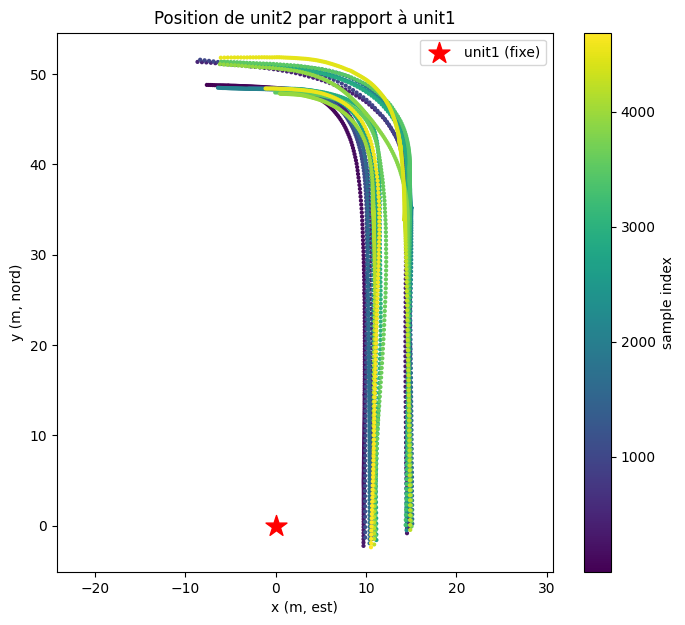

In [ ]:
plt.figure(figsize=(8, 7))
sc = plt.scatter(gps2["x_m"], gps2["y_m"], c=gps2.index, s=4, cmap="viridis")
plt.scatter(0, 0, c="red", marker="*", s=250, label="unit1 (fixe)")
plt.colorbar(sc, label="sample index")
plt.axis("equal")
plt.xlabel("x (m, est)"); plt.ylabel("y (m, nord)")
plt.title("Position de unit2 par rapport à unit1")
plt.legend()
plt.show()

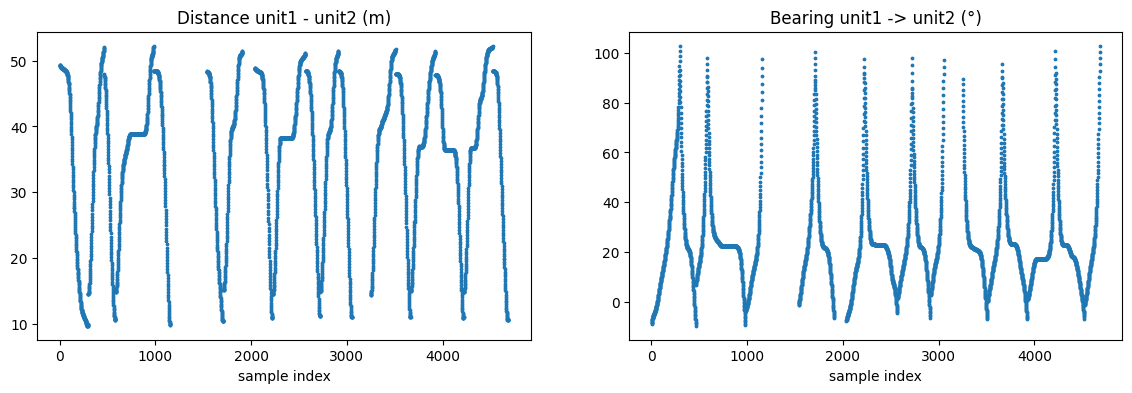

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(gps2.index, gps2["dist_m"], s=3)
ax[0].set_title("Distance unit1 - unit2 (m)"); ax[0].set_xlabel("sample index")
ax[1].scatter(gps2.index, gps2["bearing_deg"], s=3)
ax[1].set_title("Bearing unit1 -> unit2 (°)"); ax[1].set_xlabel("sample index")
plt.show()

### 2.2 Image Data

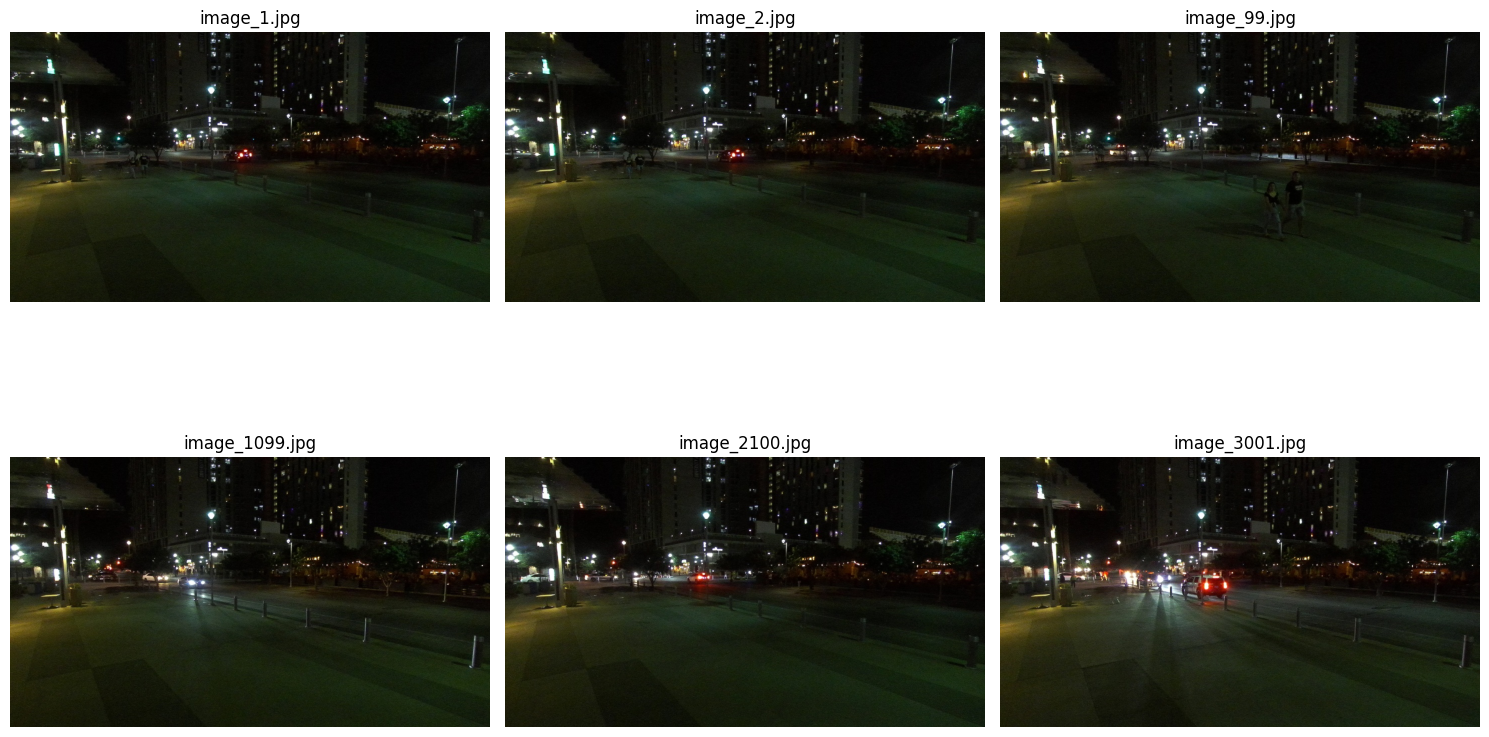

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

# List of image paths you want to plot
image_paths = [
    main_dir / "unit1" / "camera_data" / "image_1.jpg",
    main_dir / "unit1" / "camera_data" / "image_2.jpg",
    main_dir / "unit1" / "camera_data" / "image_99.jpg",
    main_dir / "unit1" / "camera_data" / "image_1099.jpg",
    main_dir / "unit1" / "camera_data" / "image_2100.jpg",
    main_dir / "unit1" / "camera_data" / "image_3001.jpg",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Use .flatten() to loop through individual axes instead of rows
for ax, path_str in zip(axes.flatten(), image_paths):
    # Read the image
    img = plt.imread(path_str)
    
    # Display the image
    ax.imshow(img)
    
    # Optional: Clean up the plot by hiding axis ticks and adding titles
    ax.axis('off')
    ax.set_title(path_str.name)

plt.tight_layout()
plt.show()

F scenario 33 mkolhom layliyya tsawer

Combien d'images?

In [ ]:
n_images = len(list((main_dir / "unit1" / "camera_data").iterdir()))
print(f"There are {n_images}/4685 ({n_images/4685:.2%})")

There are 3981/4685 (84.97%)


Nchoufou el taille mtaa les tsawer (kol wahda nafs el taille?):

In [ ]:
from PIL import Image
from collections import Counter

def img_info(p):
    with Image.open(p) as im:      # yekra ken el header, mouch kol el pixels
        return im.size, im.mode    # ((largeur, hauteur), mode)

img_files = sorted((main_dir / "unit1" / "camera_data").iterdir(), key=file_index)
Counter(img_info(p) for p in img_files)

Counter({((960, 540), 'RGB'): 3981})

### 2.3 LiDAR Data

In [ ]:
!pip install open3d

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 MB 20.5 MB/s  0:00:18m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 100.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [open3d]2m4/5 [open3d]


Ce monsieur sert a visualiser.

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


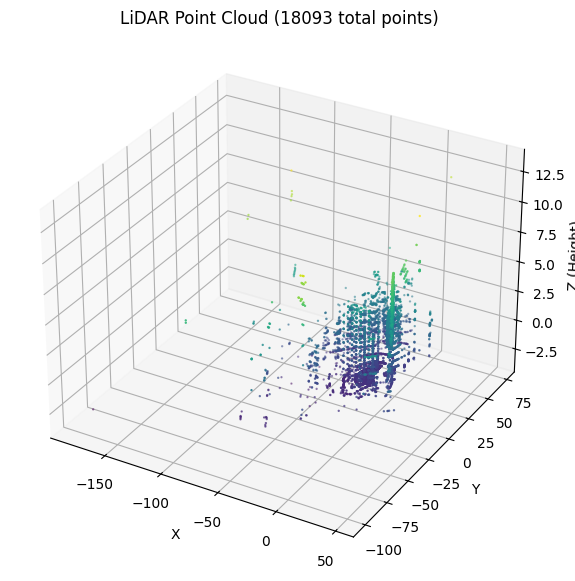

In [ ]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt

file_path = main_dir / "unit1" / "lidar_data" / "lidar_data_1.ply"
pcd = o3d.io.read_point_cloud(file_path)

points = np.asarray(pcd.points)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')

p_sub = points

scatter = ax.scatter(p_sub[:, 0], p_sub[:, 1], p_sub[:, 2], 
                     c=p_sub[:, 2], s=0.5, cmap='viridis')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z (Height)')
plt.title(f'LiDAR Point Cloud ({len(points)} total points)')
plt.show()

In [ ]:
points

array([[ 1.72622301,  0.130312  ,  0.64953912],
       [ 1.74383515,  0.13133449,  0.61299688],
       [ 1.75972329,  0.13222163,  0.57567969],
       ...,
       [ 0.2391596 ,  0.01929581, -0.04788685],
       [ 0.24961595,  0.02016286, -0.0558962 ],
       [ 0.2736048 ,  0.02201672, -0.07447086]])

In [ ]:
points.shape

(18093, 3)

Trah Njarbou marokhra

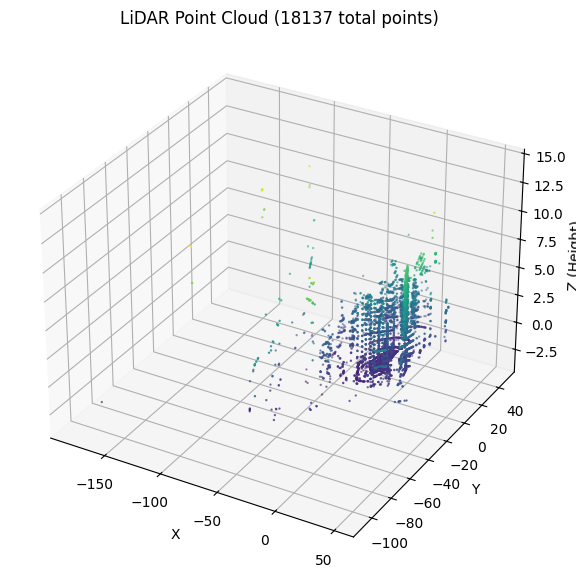

In [ ]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt

file_path = main_dir / "unit1" / "lidar_data" / "lidar_data_99.ply"
pcd = o3d.io.read_point_cloud(file_path)

points = np.asarray(pcd.points)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')


scatter = ax.scatter(points[:, 0], points[:, 1], points[:, 2], 
                     c=points[:, 2], s=0.5, cmap='viridis')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z (Height)')
plt.title(f'LiDAR Point Cloud ({len(points)} total points)')
plt.show()

In [ ]:
points.shape

(18137, 3)

✍️ (18093, 3) mahouch (18137, 3), N nombre de points yetbadel men file l file. Très important detail.

Combien de LiDARs??

In [ ]:
n_lidar = len(list((main_dir / "unit1" / "lidar_data").iterdir()))
print(f"There are {n_lidar}/4685 ({n_lidar/4685:.2%})")

There are 3981/4685 (84.97%)


encore ne9sin mais 3981 kif 9bila

Lezem nekhdhou fekra ala el min wel max wel moyenne mtaa les points.

Kol fichier LiDAR 3andou nombre de points différent, donc nhesbou les stats **par fichier** (min / max / moyenne mtaa x, y, z) w baad nchoufou kifech yetbadlou 3al fichiers lkol. Awel haja, fichier wahed:

In [ ]:
import open3d as o3d

def load_lidar(path):
    return np.asarray(o3d.io.read_point_cloud(str(path)).points)

pts = load_lidar(main_dir / "unit1" / "lidar_data" / "lidar_data_1.ply")
pd.DataFrame(pts, columns=["x", "y", "z"]).describe().round(3)

,x,y,z
count,18093.000,18093.000,18093.000
mean,-1.678,-0.274,0.302
std,11.691,11.121,1.755
min,-182.521,-100.769,-3.322
25%,-3.948,-3.289,-0.949
50%,0.017,0.176,-0.042
75%,0.319,1.576,0.283
max,48.121,72.332,13.118


Daba el fichiers lkol. Ma nekhzenouch el points lkol f RAM (~70M points): nekhdhou stats par fichier + 500 points random par fichier bech nrasmou el distribution.

In [ ]:
lidar_files = sorted((main_dir / "unit1" / "lidar_data").iterdir(), key=file_index)
rng = np.random.default_rng(0)
rows, sample = [], []

for p in lidar_files:
    pts = load_lidar(p)
    row = {"index": file_index(p), "n_points": len(pts)}
    if len(pts) > 0:
        row["has_nan"] = not np.isfinite(pts).all()
        for a, ax_name in enumerate("xyz"):
            row[f"{ax_name}_min"] = pts[:, a].min()
            row[f"{ax_name}_max"] = pts[:, a].max()
            row[f"{ax_name}_mean"] = pts[:, a].mean()
        sample.append(pts[rng.choice(len(pts), min(500, len(pts)), replace=False)])
    rows.append(row)

lidar_stats = pd.DataFrame(rows).set_index("index")
lidar_sample = np.concatenate(sample)
print(lidar_stats.shape, lidar_sample.shape)

(3981, 11) (1990500, 3)


In [ ]:
lidar_stats.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_points,3981.0,18117.18,145.27,13514.00,18077.00,18116.00,18150.00,19710.00
x_min,3981.0,-160.41,35.94,-204.88,-182.56,-182.50,-103.28,-84.52
x_max,3981.0,50.56,7.53,41.30,48.17,49.09,49.51,191.65
x_mean,3981.0,-1.62,0.15,-2.07,-1.69,-1.63,-1.56,1.04
y_min,3981.0,-107.17,6.95,-188.14,-110.44,-106.80,-102.94,-87.42
y_max,3981.0,58.53,15.55,31.11,47.41,53.27,60.29,189.26
y_mean,3981.0,-0.34,0.15,-2.81,-0.37,-0.31,-0.27,0.01
z_min,3981.0,-3.33,3.36,-72.75,-3.32,-3.32,-2.69,-1.78
z_max,3981.0,18.27,4.04,11.89,16.20,18.47,18.52,72.56
z_mean,3981.0,0.32,0.02,0.26,0.31,0.33,0.34,0.47


Nombre de points: distribution w kifech yetbadel m3a el wa9t.

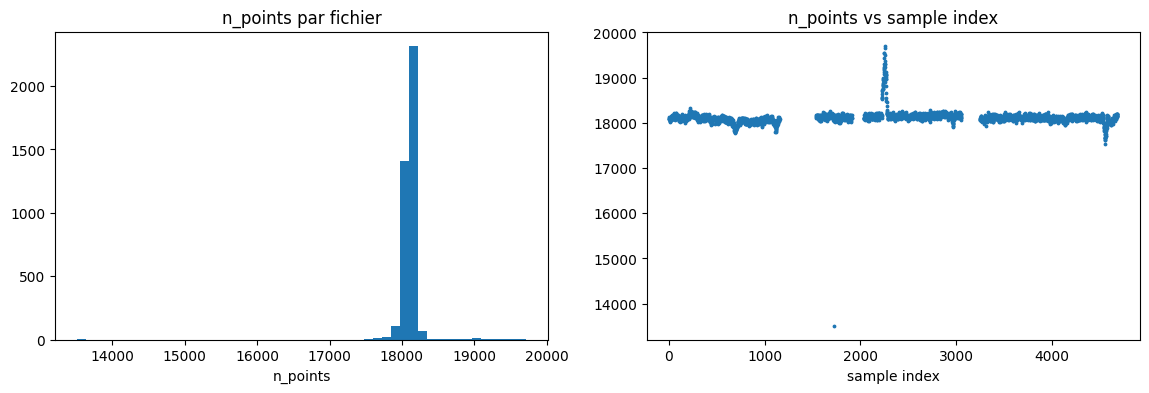

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(lidar_stats["n_points"], bins=50)
ax[0].set_title("n_points par fichier"); ax[0].set_xlabel("n_points")
ax[1].scatter(lidar_stats.index, lidar_stats["n_points"], s=3)
ax[1].set_title("n_points vs sample index"); ax[1].set_xlabel("sample index")
plt.show()

Distribution des coordonnées (points pooled mel échantillon) w vue de haut (x-y) bech nchoufou win el points yetkaw9a3ou.

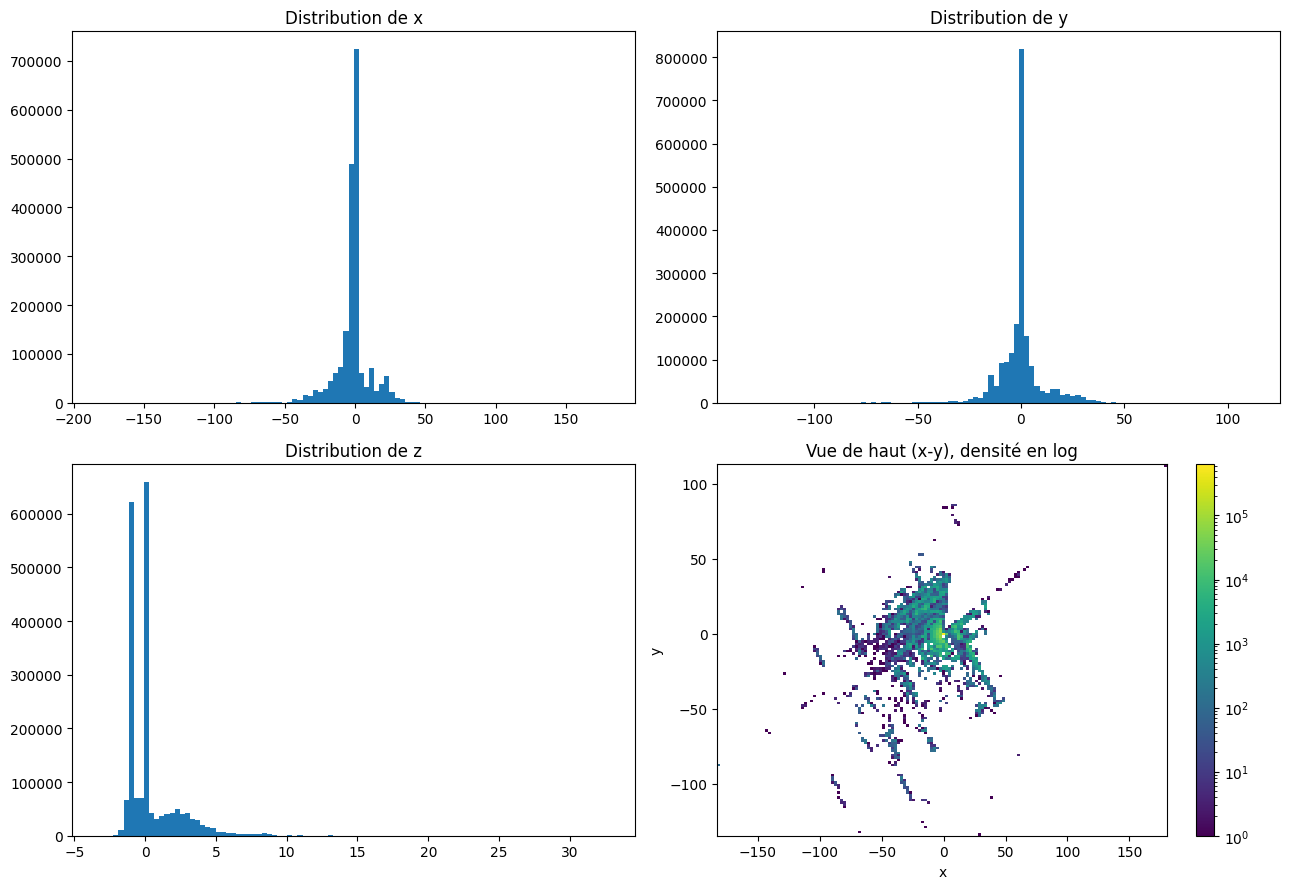

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, ax_name in enumerate("xyz"):
    axis = ax.flatten()[a]
    axis.hist(lidar_sample[:, a], bins=100)
    axis.set_title(f"Distribution de {ax_name}")
h = ax[1, 1].hist2d(lidar_sample[:, 0], lidar_sample[:, 1], bins=150, cmap="viridis", norm="log")
ax[1, 1].set_title("Vue de haut (x-y), densité en log")
ax[1, 1].set_xlabel("x"); ax[1, 1].set_ylabel("y")
plt.colorbar(h[3], ax=ax[1, 1])
plt.tight_layout()
plt.show()

### 2.4 mmWave Data

In [ ]:
with open(main_dir / "unit1" / "mmWave_data" / "mmWave_power_1.txt", "r") as f:
    print(f.read())

1.251304000616073608e-01
4.144535362720489502e-01
4.190478026866912842e-01
3.770525753498077393e-01
2.530866563320159912e-01
2.373960167169570923e-01
2.348414808511734009e-01
1.932104974985122681e-01
1.666304320096969604e-01
1.759766787290573120e-01
1.561785936355590820e-01
1.558332592248916626e-01
1.647389084100723267e-01
1.814581751823425293e-01
1.665492355823516846e-01
1.979100704193115234e-01
1.900028884410858154e-01
1.795162111520767212e-01
1.621632874011993408e-01
1.481806188821792603e-01
1.577770262956619263e-01
1.607154160737991333e-01
1.468379348516464233e-01
1.470264345407485962e-01
1.508469879627227783e-01
1.592412590980529785e-01
1.566726416349411011e-01
1.504486501216888428e-01
1.596972793340682983e-01
1.569505929946899414e-01
1.505373418331146240e-01
1.545355468988418579e-01
1.526671648025512695e-01
1.475946158170700073e-01
1.516447514295578003e-01
1.600627452135086060e-01
1.517462283372879028e-01
1.681269556283950806e-01
1.919129788875579834e-01
1.633147001266479492e-01


to array

In [ ]:
with open(main_dir / "unit1" / "mmWave_data" / "mmWave_power_1.txt", "r") as f:
    lines = []
    for line in f:
        lines.append(float(line))
print(lines[0])

0.12513040006160736


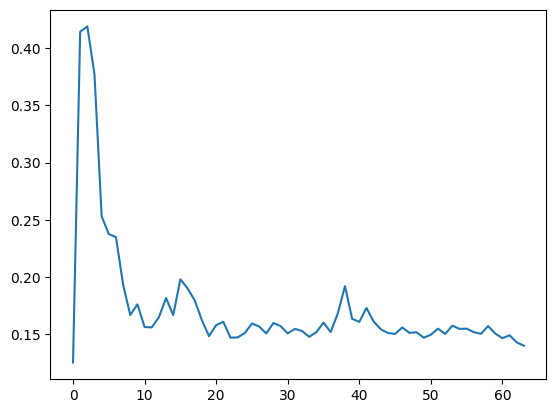

In [ ]:
plt.plot(range(len(lines)), lines)
plt.show()

Hmmm, let's try again

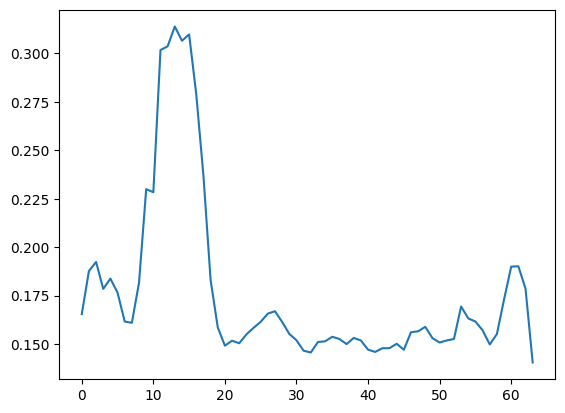

In [ ]:
with open(main_dir / "unit1" / "mmWave_data" / "mmWave_power_99.txt", "r") as f:
    lines = []
    for line in f:
        lines.append(float(line))

plt.plot(range(len(lines)), lines)
plt.show()

Trah nchoufou kadech men data point

In [ ]:
n_mmwave = len(list((main_dir / "unit1" / "mmWave_data").iterdir()))
print(f"There are {n_mmwave}/4685 ({n_mmwave/4685:.2%})")

There are 3981/4685 (84.97%)


kelaada meme nombre

Kol fichier = 64 valeurs = puissance reçue 3la kol beam (beam 1 -> 64). Nlemmouhom lkol f matrice (samples x 64):

In [ ]:
mm_files = sorted((main_dir / "unit1" / "mmWave_data").iterdir(), key=file_index)
pwr_rows = {file_index(p): np.loadtxt(p) for p in mm_files}

lengths = {len(v) for v in pwr_rows.values()}
print("Longueurs des fichiers:", lengths)
n_beams = lengths.pop()

pwr = pd.DataFrame.from_dict(pwr_rows, orient="index", columns=range(1, n_beams + 1)).sort_index()
pwr.index.name = "index"
print(pwr.shape)

Longueurs des fichiers: {64}
(3981, 64)


In [ ]:
vals = pwr.to_numpy()
print(f"NaN: {np.isnan(vals).sum()} | min={vals.min():.4f} | max={vals.max():.4f} | mean={vals.mean():.4f} | std={vals.std():.4f}")

NaN: 62 | min=nan | max=nan | mean=nan | std=nan


Puissance moyenne par beam (± 1 std):

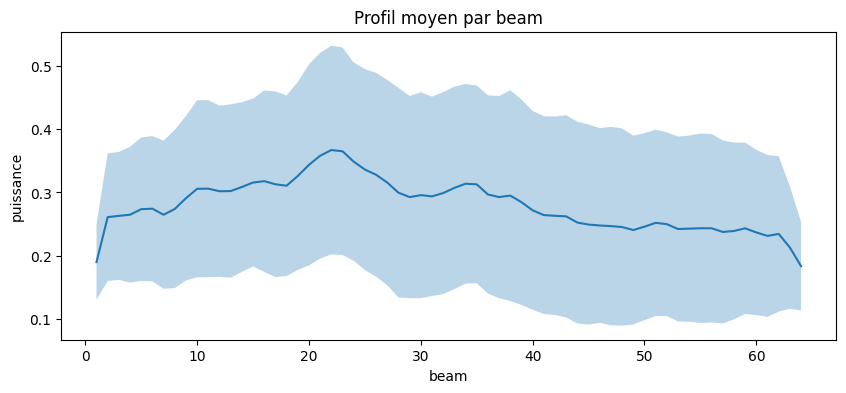

In [ ]:
m, s = pwr.mean().to_numpy(), pwr.std().to_numpy()
plt.figure(figsize=(10, 4))
plt.plot(pwr.columns, m)
plt.fill_between(pwr.columns, m - s, m + s, alpha=0.3)
plt.xlabel("beam"); plt.ylabel("puissance")
plt.title("Profil moyen par beam")
plt.show()

Heatmap: x = sample, y = beam. Kol colonne = mesure wahda; el ligne esskhouna = best beam. Les colonnes vides = les trous (index manquants).

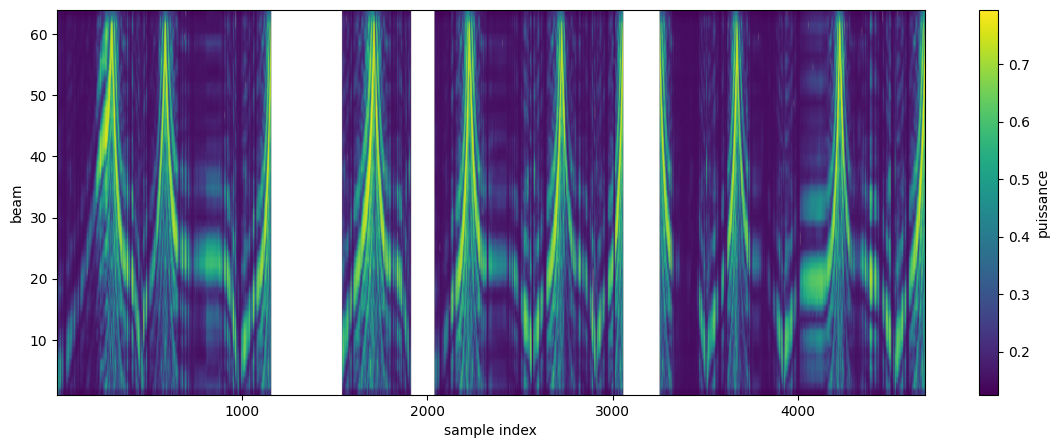

In [ ]:
full = pwr.reindex(range(pwr.index.min(), pwr.index.max() + 1))   # NaN lel index manquants
plt.figure(figsize=(14, 5))
plt.imshow(full.T.to_numpy(), aspect="auto", origin="lower", cmap="viridis",
           extent=[full.index.min(), full.index.max(), 1, n_beams])
plt.colorbar(label="puissance")
plt.xlabel("sample index"); plt.ylabel("beam")
plt.show()

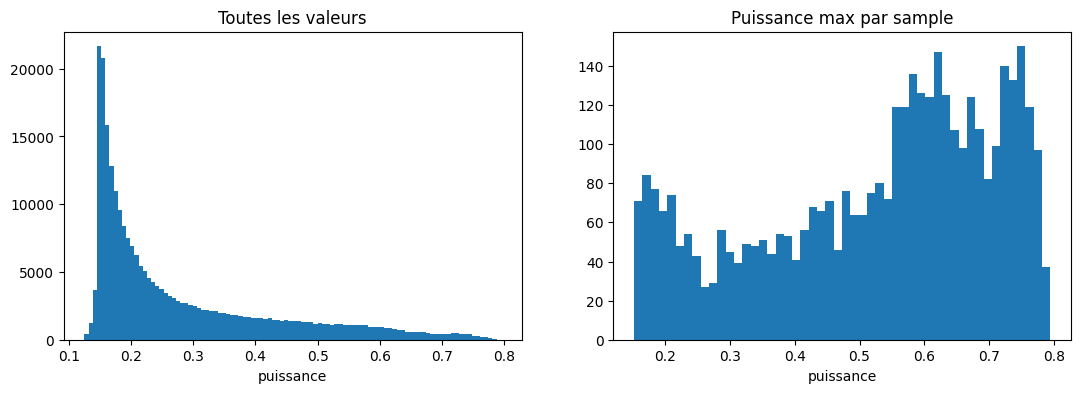

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(vals.flatten(), bins=100)
ax[0].set_title("Toutes les valeurs"); ax[0].set_xlabel("puissance")
ax[1].hist(pwr.max(axis=1), bins=50)
ax[1].set_title("Puissance max par sample"); ax[1].set_xlabel("puissance")
plt.show()

### 2.5 Radar Data

In [ ]:
import numpy as np
from pathlib import Path


radar_path = main_dir / "unit1" / "radar_data" / "radar_data_1.npy"
radar_data = np.load(radar_path)


print("Array shape:", radar_data.shape)
print("Data type:", radar_data.dtype)


print(radar_data[:5])

Array shape: (4, 256, 250)
Data type: complex64
[[[-1.6479492e-03+1.5411377e-03j -1.5258789e-03+1.4343262e-03j
   -1.4801025e-03+1.3275146e-03j ... -1.4038086e-03+1.3427734e-03j
   -1.6174316e-03+1.6021729e-03j -1.5869141e-03+1.3427734e-03j]
  [-1.5106201e-03+1.5716553e-03j -1.0070801e-03+1.6937256e-03j
   -9.4604492e-04+1.8615723e-03j ... -1.0070801e-03+1.4953613e-03j
   -1.0223389e-03+1.8157959e-03j -1.0375977e-03+1.2969971e-03j]
  [-1.5411377e-03+1.3885498e-03j -1.3580322e-03+1.4495850e-03j
   -1.2359619e-03+1.3732910e-03j ... -1.3732910e-03+1.3275146e-03j
   -1.2664795e-03+1.1901855e-03j -1.5411377e-03+1.3427734e-03j]
  ...
  [-2.2888184e-04+1.6784668e-04j  3.0517578e-05+1.3732910e-04j
   -2.4414062e-04-1.5258789e-05j ... -1.6784668e-04+1.5258789e-05j
   -1.0681152e-04-4.5776367e-05j -6.1035156e-05+1.5258789e-05j]
  [ 1.3732910e-04-2.2888184e-04j  9.1552734e-05-4.5776367e-05j
    1.6784668e-04-3.3569336e-04j ...  1.2207031e-04-1.3732910e-04j
    2.7465820e-04+4.5776367e-05j  1.5258

* **Data Shape `(4, 256, 250)`:**
* **4 Antennas & 256 Range Bins:** Capture receive channels for spatial angle and distance measurements.
* **250 Chirps:** Track velocity over time using the Doppler effect.


* **How to Use It:** Convert the complex values into real numbers using magnitude (`np.abs()`), then process them into 2D Range-Doppler or Range-Angle maps to feed into machine learning models.

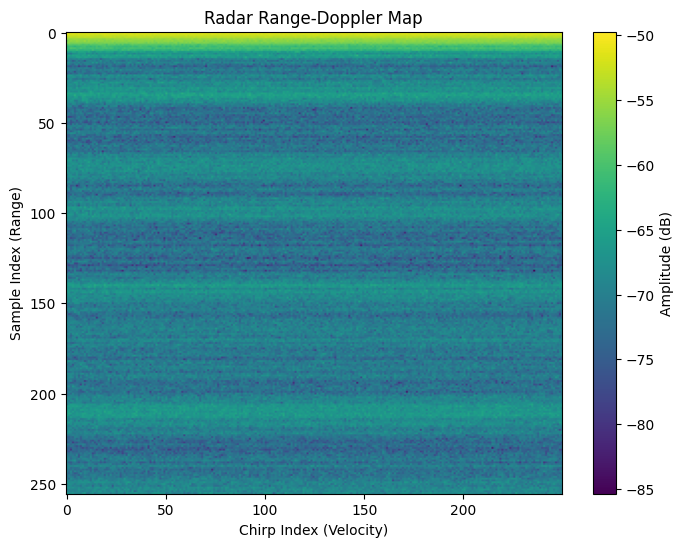

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

range_doppler_map = np.mean(np.abs(radar_data), axis=0)


plt.figure(figsize=(8, 6))
plt.imshow(20 * np.log10(range_doppler_map + 1e-6), aspect='auto', cmap='viridis')
plt.colorbar(label='Amplitude (dB)')
plt.xlabel('Chirp Index (Velocity)')
plt.ylabel('Sample Index (Range)')
plt.title('Radar Range-Doppler Map')
plt.show()

This can be used like image data :) ama kayennou el moyenne ala les antennes bech ykhasarna directional information, trah njarbou bel FFT.

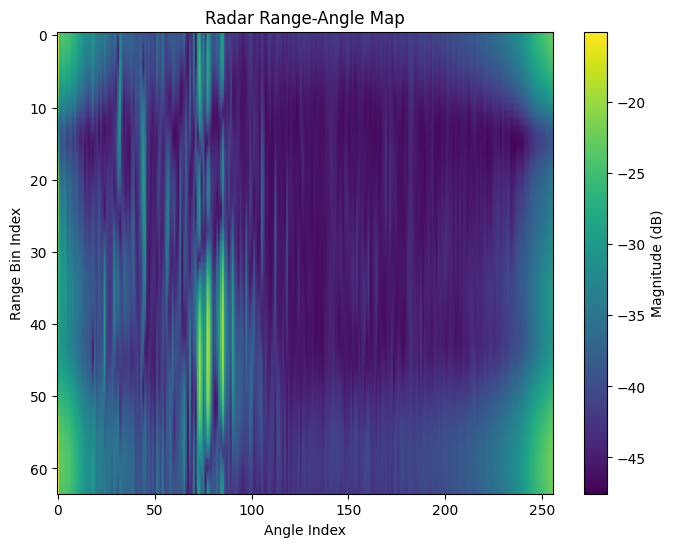

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 2. Range FFT along the sample axis (axis=1)
range_fft = np.fft.fft(radar_data, axis=1)

# 3. Angle FFT along the antenna axis (axis=0) with zero-padding to 64 points
angle_fft = np.fft.fft(range_fft, n=64, axis=0)

# 4. Collapse the chirp dimension (axis=2) by taking the mean magnitude
range_angle_map = np.mean(np.abs(angle_fft), axis=2)

# Shift the center angle to the middle of the plot
range_angle_map = np.fft.fftshift(range_angle_map, axes=0)

# 5. Plot the resulting Range-Angle heatmap
plt.figure(figsize=(8, 6))
plt.imshow(20 * np.log10(range_angle_map + 1e-6), aspect='auto', cmap='viridis')
plt.colorbar(label='Magnitude (dB)')
plt.xlabel('Angle Index')
plt.ylabel('Range Bin Index')
plt.title('Radar Range-Angle Map')
plt.show()

In [ ]:
import numpy as np
import torch

# 1. Load raw data: shape (4 antennas, 256 samples, 250 chirps)
radar_data = np.load(radar_path)

# 2. Range FFT along the sample axis (axis=1) to get distance
range_fft = np.fft.fft(radar_data, axis=1)

# 3. Doppler FFT along the chirp axis (axis=2) to get velocity/spectrogram
doppler_fft = np.fft.fft(range_fft, axis=2)

# 4. Shift zero-velocity to the center of the map for readability
doppler_fft = np.fft.fftshift(doppler_fft, axes=2)

# 5. Take magnitude and convert to log scale (dB)
radar_spectrogram = 20 * np.log10(np.abs(doppler_fft) + 1e-6)

print(radar_spectrogram.shape, radar_spectrogram)

(4, 256, 250) [[[-30.159006 -32.29502  -25.791508 ... -31.567764 -25.645607 -31.2432  ]
  [-26.734566 -35.47307  -30.72073  ... -31.565742 -33.31345  -52.813946]
  [-35.894375 -28.520128 -30.911602 ... -35.43563  -33.308014 -33.595177]
  ...
  [-43.59892  -30.287712 -39.33293  ... -33.939552 -34.48814  -28.458542]
  [-31.447556 -33.825207 -41.362778 ... -44.403    -33.295864 -34.63207 ]
  [-31.401016 -30.107918 -35.88623  ... -38.347183 -34.061825 -57.83779 ]]

 [[-24.86259  -29.730038 -26.263977 ... -26.056015 -38.564014 -27.977182]
  [-35.968853 -28.200226 -29.216673 ... -37.975685 -30.496311 -28.562057]
  [-31.35759  -32.828705 -28.692513 ... -34.997585 -30.745432 -37.41306 ]
  ...
  [-39.12888  -35.57553  -27.012371 ... -38.86946  -28.694576 -41.33043 ]
  [-28.119728 -29.262278 -35.187794 ... -34.68418  -35.220833 -32.619614]
  [-33.083122 -35.13389  -30.240715 ... -31.653008 -36.189205 -29.71322 ]]

 [[-32.562813 -52.047844 -30.936676 ... -27.709753 -35.64379  -32.964703]
  [-35.4

Hedhom 3 types de mesures najmou nesta3mlouhom? Najmou njarbouhom ala small models w nchoufou chniya ahsen combo.

In [ ]:
n_radar = len(list((main_dir / "unit1" / "radar_data").iterdir()))
print(f"There are {n_radar}/4685 ({n_radar/4685:.2%})")

There are 3981/4685 (84.97%)


Kol fichier radar = 4x256x250 complex64 = ~ 2 MB, donc ~ 8 GB lkol: ma nlemmouhomch f RAM. Par fichier nekhdhou: magnitude moyenne/max (global w par antenne), check NaN, w **range profile** (256 valeurs) bech nchoufou el cible tetharek m3a el wa9t. Chwaya w9at (~ 1 à 2 min).

In [ ]:
radar_files = sorted((main_dir / "unit1" / "radar_data").iterdir(), key=file_index)
rows, range_prof = [], []
shapes, dtypes = set(), set()

for p in radar_files:
    r = np.load(p)
    shapes.add(r.shape); dtypes.add(str(r.dtype))
    mag = np.abs(r)                                     # (4, 256, 250)
    row = {"index": file_index(p), "has_nan": bool(np.isnan(r).any()),
           "mean_abs": mag.mean(), "max_abs": mag.max()}
    for a in range(mag.shape[0]):
        row[f"ant{a}_mean_abs"] = mag[a].mean()
    rows.append(row)
    range_prof.append(np.abs(np.fft.fft(r, axis=1)).mean(axis=(0, 2)))   # (256,)

radar_stats = pd.DataFrame(rows).set_index("index")
range_prof = pd.DataFrame(np.array(range_prof), index=radar_stats.index)
print("shapes:", shapes, "| dtypes:", dtypes)

shapes: {(4, 256, 250)} | dtypes: {'complex64'}


In [ ]:
radar_stats.describe().T

,count,mean,std,min,25%,50%,75%,max
mean_abs,3981.0,0.000360,0.000026,0.000281,0.000351,0.000373,0.000380,0.000457
max_abs,3981.0,0.006221,0.000147,0.005666,0.006121,0.006222,0.006321,0.006710
ant0_mean_abs,3981.0,0.000335,0.000021,0.000268,0.000324,0.000343,0.000350,0.000414
ant1_mean_abs,3981.0,0.000301,0.000029,0.000217,0.000293,0.000313,0.000322,0.000410
ant2_mean_abs,3981.0,0.000446,0.000026,0.000367,0.000435,0.000455,0.000465,0.000545
ant3_mean_abs,3981.0,0.000359,0.000031,0.000264,0.000343,0.000372,0.000382,0.000459


El 4 antennes mtawazna? W el magnitude moyenne fel wa9t:

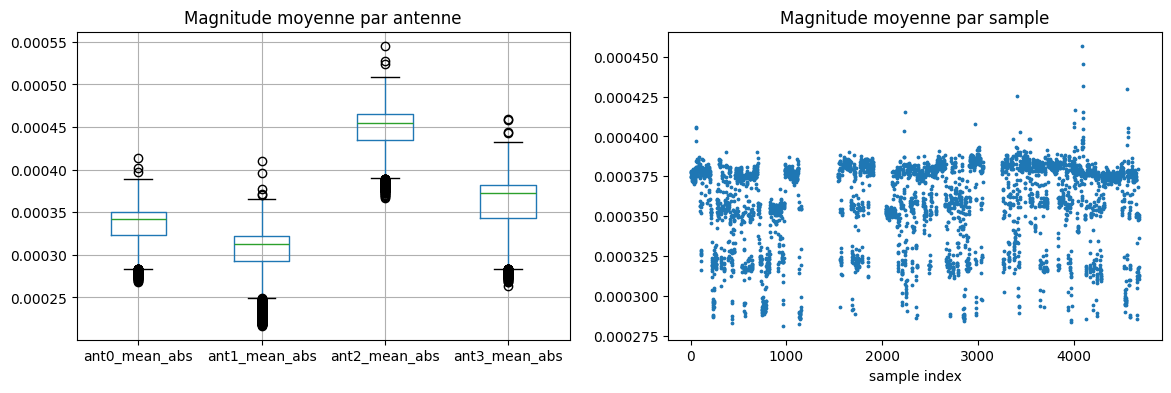

In [ ]:
ant_cols = [c for c in radar_stats.columns if c.startswith("ant")]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
radar_stats[ant_cols].boxplot(ax=ax[0])
ax[0].set_title("Magnitude moyenne par antenne")
ax[1].scatter(radar_stats.index, radar_stats["mean_abs"], s=3)
ax[1].set_title("Magnitude moyenne par sample"); ax[1].set_xlabel("sample index")
plt.show()

Range profile fel wa9t (x = sample, y = range bin, couleur = dB). Les colonnes vides = les trous.

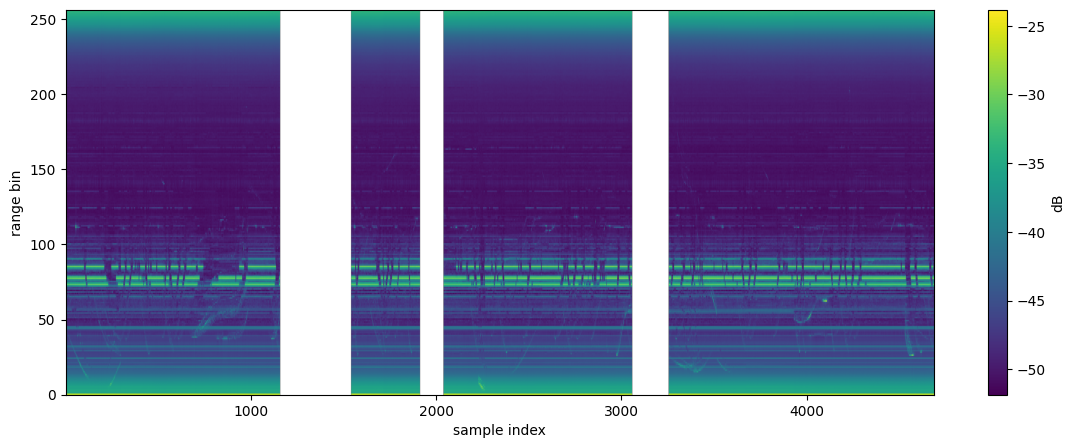

In [ ]:
full = range_prof.reindex(range(range_prof.index.min(), range_prof.index.max() + 1))
plt.figure(figsize=(14, 5))
plt.imshow(20 * np.log10(full.T.to_numpy() + 1e-6), aspect="auto", origin="lower", cmap="viridis",
           extent=[full.index.min(), full.index.max(), 0, full.shape[1]])
plt.colorbar(label="dB")
plt.xlabel("sample index"); plt.ylabel("range bin")
plt.show()

### 2.6 Unit2 GPS Location

In [ ]:
with open(main_dir / "unit2" / "GPS_data" / "GPS_location_1.txt", "r") as f:
    x, y = list(f)
    x, y = float(x), float(y)
    print(x, y)

33.42432322666667 -111.93520185


trah nlemmou locations lkol

In [ ]:
# FIX: el loop l9dim kan yakra GPS_location_1.txt f koll iteration (donc kol points kenou nafs el point).
# tawa nesta3mlou gps2 (déjà loadé f 2.1): X = latitude, Y = longitude
X, Y = gps2["lat"].tolist(), gps2["lon"].tolist()

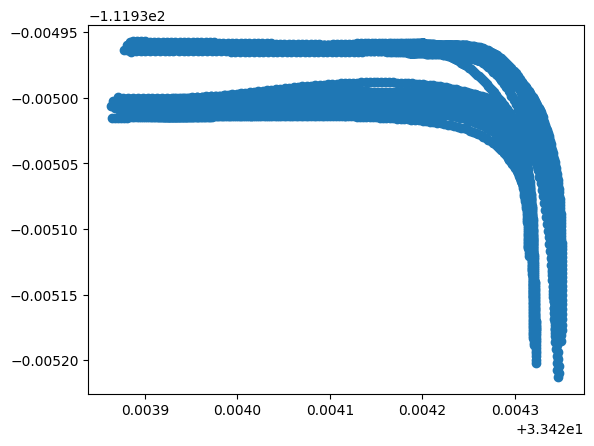

In [ ]:
plt.scatter(X, Y)
plt.show()

In [ ]:
n_distinct = gps2[["lat", "lon"]].drop_duplicates().shape[0]
print(f"Positions distinctes: {n_distinct}/{len(gps2)}")
print(f"Étendue: {gps2['x_m'].max() - gps2['x_m'].min():.0f} m (est-ouest) x {gps2['y_m'].max() - gps2['y_m'].min():.0f} m (nord-sud)")

Positions distinctes: 3961/3981
Étendue: 24 m (est-ouest) x 54 m (nord-sud)


## 3. Stage el Wa7ch, CSV File

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv(main_dir / "scenario33_dev.csv", index_col=0)
df

,unit1_rgb,unit1_pwr_60ghz,unit1_lidar,unit1_radar,unit1_loc,unit2_loc,unit1_beam,unit1_max_pwr,time_stamp,seq_index,unit2_spd_over_grnd_kmph,unit2_num_sats,unit2_altitude,unit2_geo_sep,unit2_mode_fix_type,unit2_pdop,unit2_hdop,unit2_vdop,unit2_interpolated_position
index,,,,,,,,,,,,,,,,,,,
1,./unit1/camera_data/image_1.jpg,./unit1/mmWave_data/mmWave_power_1.txt,./unit1/lidar_data/lidar_data_1.ply,./unit1/radar_data/radar_data_1.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_1.txt,3,0.419048,04:09:06-325991,1,7.997,12.0,355.907,-27.749,3.0,1.06,0.59,0.88,0
2,./unit1/camera_data/image_2.jpg,./unit1/mmWave_data/mmWave_power_2.txt,./unit1/lidar_data/lidar_data_2.ply,./unit1/radar_data/radar_data_2.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_2.txt,2,0.530836,04:09:06-418775,1,7.676,12.0,355.905,-27.749,3.0,1.06,0.59,0.88,0
3,./unit1/camera_data/image_3.jpg,./unit1/mmWave_data/mmWave_power_3.txt,./unit1/lidar_data/lidar_data_3.ply,./unit1/radar_data/radar_data_3.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_3.txt,4,0.558496,04:09:06-510460,1,7.560,12.0,355.900,-27.749,3.0,1.06,0.59,0.88,0
4,./unit1/camera_data/image_4.jpg,./unit1/mmWave_data/mmWave_power_4.txt,./unit1/lidar_data/lidar_data_4.ply,./unit1/radar_data/radar_data_4.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_4.txt,3,0.458776,04:09:06-601724,1,7.347,12.0,355.897,-27.749,3.0,1.06,0.59,0.88,0
5,./unit1/camera_data/image_5.jpg,./unit1/mmWave_data/mmWave_power_5.txt,./unit1/lidar_data/lidar_data_5.ply,./unit1/radar_data/radar_data_5.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_5.txt,3,0.392710,04:09:06-693246,1,7.365,12.0,355.890,-27.749,3.0,1.06,0.59,0.88,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4681,./unit1/camera_data/image_4681.jpg,./unit1/mmWave_data/mmWave_power_4681.txt,./unit1/lidar_data/lidar_data_4681.ply,./unit1/radar_data/radar_data_4681.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_4681.txt,55,0.794149,04:45:06-982931,21,16.552,12.0,355.544,-27.750,3.0,1.07,0.54,0.92,0
4682,./unit1/camera_data/image_4682.jpg,./unit1/mmWave_data/mmWave_power_4682.txt,./unit1/lidar_data/lidar_data_4682.ply,./unit1/radar_data/radar_data_4682.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_4682.txt,55,0.787625,04:45:07-073256,21,16.498,12.0,355.533,-27.750,3.0,1.07,0.54,0.92,0
4683,./unit1/camera_data/image_4683.jpg,./unit1/mmWave_data/mmWave_power_4683.txt,./unit1/lidar_data/lidar_data_4683.ply,./unit1/radar_data/radar_data_4683.npy,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_4683.txt,57,0.784775,04:45:07-164599,21,16.586,12.0,355.531,-27.750,3.0,1.02,0.53,0.88,0


In [ ]:
df.columns

Index(['unit1_rgb', 'unit1_pwr_60ghz', 'unit1_lidar', 'unit1_radar',
       'unit1_loc', 'unit2_loc', 'unit1_beam', 'unit1_max_pwr', 'time_stamp',
       'seq_index', 'unit2_spd_over_grnd_kmph', 'unit2_num_sats',
       'unit2_altitude', 'unit2_geo_sep', 'unit2_mode_fix_type', 'unit2_pdop',
       'unit2_hdop', 'unit2_vdop', 'unit2_interpolated_position'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3981 entries, 1 to 4685
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   unit1_rgb                    3981 non-null   object 
 1   unit1_pwr_60ghz              3981 non-null   object 
 2   unit1_lidar                  3981 non-null   object 
 3   unit1_radar                  3981 non-null   object 
 4   unit1_loc                    3981 non-null   object 
 5   unit2_loc                    3981 non-null   object 
 6   unit1_beam                   3981 non-null   int64  
 7   unit1_max_pwr                3981 non-null   float64
 8   time_stamp                   3981 non-null   object 
 9   seq_index                    3981 non-null   int64  
 10  unit2_spd_over_grnd_kmph     3679 non-null   float64
 11  unit2_num_sats               3679 non-null   float64
 12  unit2_altitude               3679 non-null   float64
 13  unit2_geo_sep          

### 3.1 Valeurs manquantes w colonnes inutiles

In [ ]:
df.isna().sum()[lambda s: s > 0]

unit2_spd_over_grnd_kmph    302
unit2_num_sats              302
unit2_altitude              302
unit2_geo_sep               302
unit2_mode_fix_type         302
unit2_pdop                  302
unit2_hdop                  302
unit2_vdop                  302
dtype: int64

302 ligne (3981 - 3679) fihom NaN fel 8 colonnes GPS mtaa unit2. Nchoufou ken houma nafs el lignes w ken 3andhom 3ala9a bel `interpolated_position`:

In [ ]:
gps_extra = ["unit2_spd_over_grnd_kmph", "unit2_num_sats", "unit2_altitude", "unit2_geo_sep",
             "unit2_mode_fix_type", "unit2_pdop", "unit2_hdop", "unit2_vdop"]
print("NaN f nafs el lignes (toutes ou aucune):", df[gps_extra].isna().sum(axis=1).isin([0, len(gps_extra)]).all())
pd.crosstab(df["unit2_interpolated_position"], df["unit2_spd_over_grnd_kmph"].isna(),
            rownames=["interpolated"], colnames=["NaN"])

NaN f nafs el lignes (toutes ou aucune): True


NaN,False,True
interpolated,,
0,3679,0
1,0,302


Nope

Nombre de valeurs distinctes par colonne. Colonne b valeur wahda (ou presque) = ma fihech information.

In [ ]:
df.nunique().sort_values()

unit1_loc                         1
unit2_num_sats                    1
unit2_geo_sep                     2
unit2_mode_fix_type               2
unit2_interpolated_position       2
unit2_hdop                       13
seq_index                        18
unit2_vdop                       26
unit2_pdop                       27
unit1_beam                       63
unit2_altitude                 1053
unit2_spd_over_grnd_kmph       3188
time_stamp                     3959
unit1_max_pwr                  3959
unit1_rgb                      3981
unit2_loc                      3981
unit1_radar                    3981
unit1_lidar                    3981
unit1_pwr_60ghz                3981
dtype: int64

In [ ]:
num_cols = df.select_dtypes("number").columns
df[num_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
unit1_beam,3981.0,23.020,11.694,2.000,16.000,22.000,27.000,64.000
unit1_max_pwr,3981.0,0.527,0.182,0.152,0.393,0.572,0.676,0.794
seq_index,3981.0,11.248,6.493,1.000,5.000,11.000,18.000,21.000
unit2_spd_over_grnd_kmph,3679.0,10.151,6.554,0.000,4.493,9.634,16.172,21.971
unit2_num_sats,3679.0,12.000,0.000,12.000,12.000,12.000,12.000,12.000
unit2_altitude,3679.0,355.554,0.305,354.977,355.356,355.537,355.722,356.184
unit2_geo_sep,3679.0,-27.749,0.000,-27.750,-27.749,-27.749,-27.749,-27.749
unit2_mode_fix_type,3679.0,2.949,0.389,0.000,3.000,3.000,3.000,3.000
unit2_pdop,3679.0,0.961,0.135,0.000,0.960,0.980,0.990,1.150
unit2_hdop,3679.0,0.529,0.074,0.000,0.530,0.530,0.550,0.590


### 3.2 Index w sequences

In [ ]:
all_idx = pd.RangeIndex(df.index.min(), df.index.max() + 1)
missing = all_idx.difference(df.index)
print(f"index {df.index.min()} -> {df.index.max()} | présents: {len(df)} | manquants: {len(missing)}")

index 1 -> 4685 | présents: 3981 | manquants: 704


Les index manquants: blocs consécutifs wala dispersés?

In [ ]:
m = pd.Series(missing)
block_id = (m.diff() != 1).cumsum()
gaps = m.groupby(block_id).agg(["min", "max", "count"])
print(f"{len(gaps)} bloc(s) manquant(s)")
gaps.sort_values("count", ascending=False).head(10)

3 bloc(s) manquant(s)


,min,max,count
1,1156,1537,382
3,3054,3249,196
2,1910,2035,126


Les sequences (`seq_index`): win yebdaw w yekmlou, w 9adeh men sample manquant dakhel kol sequence (`trous`).

In [ ]:
seq = df.index.to_series().groupby(df["seq_index"]).agg(["min", "max", "count"])
seq["trous"] = seq["max"] - seq["min"] + 1 - seq["count"]
seq

,min,max,count,trous
seq_index,,,,
1,1,296,296,0
2,297,464,168,0
3,465,583,119,0
4,584,982,399,0
5,983,1155,173,0
7,1538,1710,173,0
8,1711,1909,199,0
10,2036,2223,188,0
11,2224,2568,345,0


### 3.3 Temps

In [ ]:
t = pd.to_datetime(df["time_stamp"].str.replace("-", ".", n=1), format="%H:%M:%S.%f")
df["t_sec"] = (t - t.iloc[0]).dt.total_seconds()      # secondes depuis el awel sample
dt = df["t_sec"].diff()
print(f"durée: {df['t_sec'].iloc[-1] / 60:.1f} min | temps décroissant: {(dt < 0).sum()} fois | fréquence médiane: {1 / dt.median():.1f} Hz")
dt.describe(percentiles=[.5, .99])

durée: 36.0 min | temps décroissant: 0 fois | fréquence médiane: 10.9 Hz


count    3980.000000
mean        0.542993
std         7.748615
min         0.000000
50%         0.091822
99%         0.185990
max       274.000077
Name: t_sec, dtype: float64

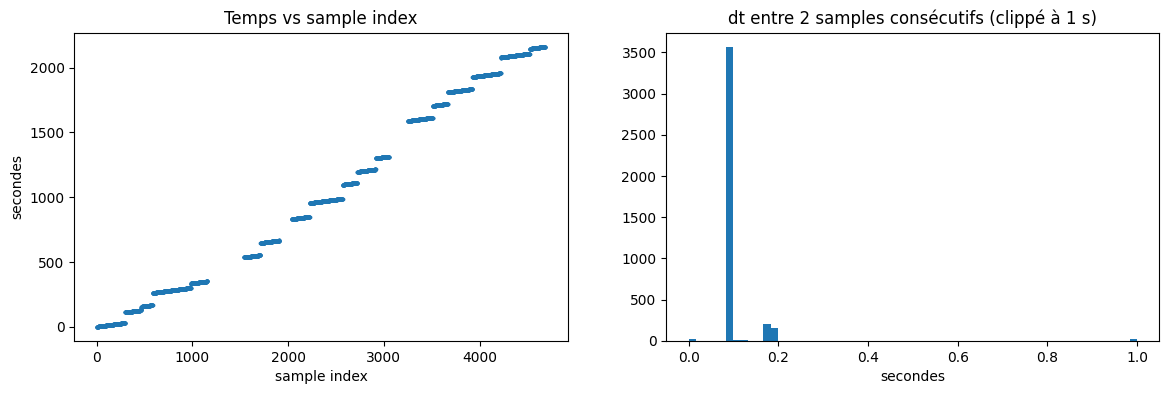

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(df.index, df["t_sec"], s=3)
ax[0].set_title("Temps vs sample index"); ax[0].set_xlabel("sample index"); ax[0].set_ylabel("secondes")
ax[1].hist(dt.dropna().clip(upper=1), bins=60)
ax[1].set_title("dt entre 2 samples consécutifs (clippé à 1 s)"); ax[1].set_xlabel("secondes")
plt.show()

### 3.4 Le label: `unit1_beam`

beam min=2 max=64 | beams jamais utilisés: 1/64


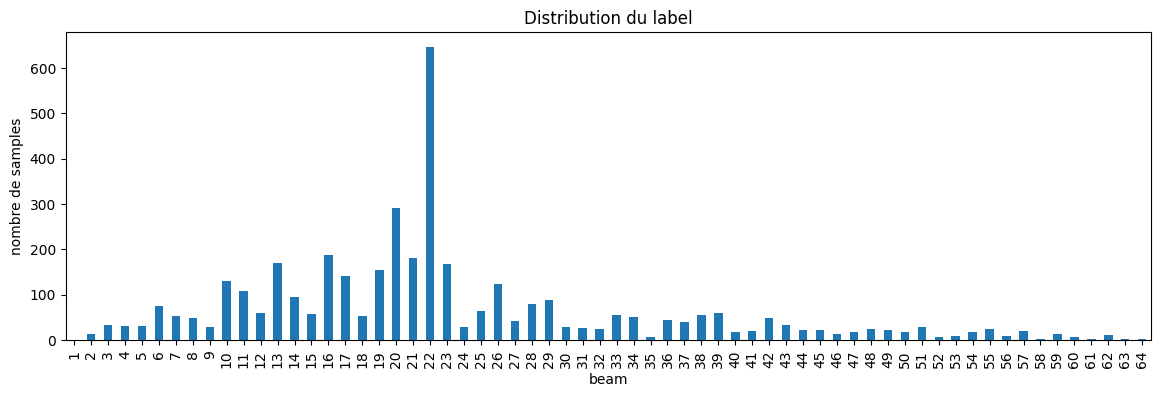

In [ ]:
n_beams = pwr.shape[1]
beam_counts = df["unit1_beam"].value_counts().reindex(range(1, n_beams + 1), fill_value=0)
print(f"beam min={df['unit1_beam'].min()} max={df['unit1_beam'].max()} | beams jamais utilisés: {(beam_counts == 0).sum()}/{n_beams}")
beam_counts.plot.bar(figsize=(14, 4))
plt.xlabel("beam"); plt.ylabel("nombre de samples"); plt.title("Distribution du label")
plt.show()

El beam fel wa9t (couleur = sequence) w kadech yetbadel binet 2 samples consécutifs:

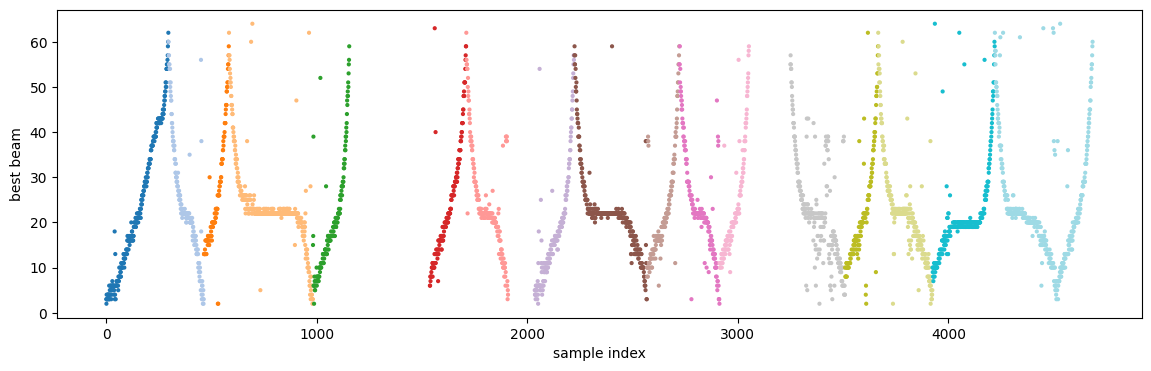

In [ ]:
plt.figure(figsize=(14, 4))
plt.scatter(df.index, df["unit1_beam"], c=df["seq_index"], cmap="tab20", s=4)
plt.xlabel("sample index"); plt.ylabel("best beam")
plt.show()

In [ ]:
dbeam = df.groupby("seq_index")["unit1_beam"].diff().abs()   # |changement| dakhel nafs el sequence (m3a el trous)
dbeam.describe(percentiles=[.5, .9, .99])

count    3963.000000
mean        2.201615
std         5.992463
min         0.000000
50%         1.000000
90%         3.000000
99%        35.000000
max        56.000000
Name: unit1_beam, dtype: float64

Ken |Δbeam| sghir fel ghaleb, ya3ni les samples el 9rab ma ba3dhom yet-ressemblou barcha. Fi el cas hedha, el split train/val lezem ykoun **par sequence** (`seq_index`) mouch random, sinon nfouti leakage.

`unit1_max_pwr`: distribution w relation m3a el beam.

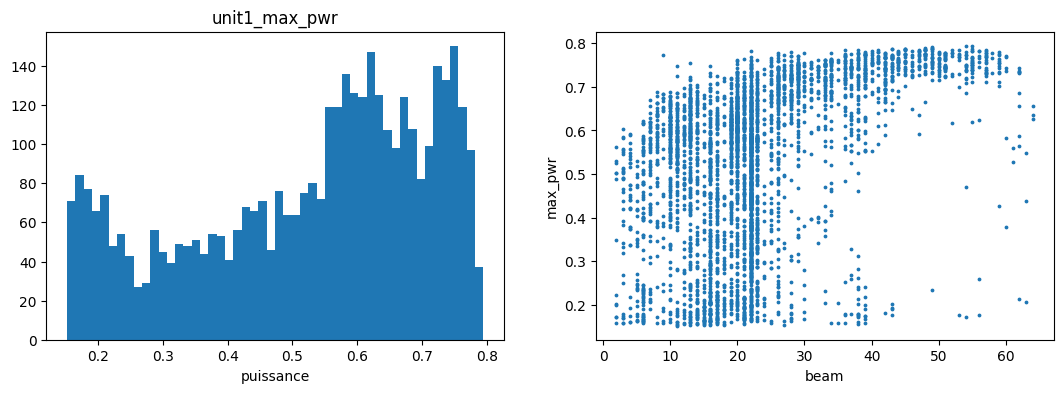

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df["unit1_max_pwr"], bins=50)
ax[0].set_title("unit1_max_pwr"); ax[0].set_xlabel("puissance")
ax[1].scatter(df["unit1_beam"], df["unit1_max_pwr"], s=3)
ax[1].set_xlabel("beam"); ax[1].set_ylabel("max_pwr")
plt.show()

### 3.5 Cohérence entre CSV w les fichiers

In [ ]:
p = pwr.loc[df.index]
print("beam == beam li fih max mmWave:", (p.idxmax(axis=1) == df["unit1_beam"]).mean())
print("max_pwr == max mmWave         :", np.allclose(p.max(axis=1).to_numpy(), df["unit1_max_pwr"].to_numpy(), atol=1e-5))

beam == beam li fih max mmWave: 0.990454659633258
max_pwr == max mmWave         : True


In [ ]:
print("index GPS unit2 == index CSV:", set(gps2.index) == set(df.index))
for c in ["unit1_rgb", "unit1_pwr_60ghz", "unit1_lidar", "unit1_radar", "unit1_loc", "unit2_loc"]:
    print(f"{c:16s} -> tous les fichiers existent:", df[c].map(lambda f: (main_dir / f).exists()).all())

index GPS unit2 == index CSV: True
unit1_rgb        -> tous les fichiers existent: True
unit1_pwr_60ghz  -> tous les fichiers existent: True
unit1_lidar      -> tous les fichiers existent: True
unit1_radar      -> tous les fichiers existent: True
unit1_loc        -> tous les fichiers existent: True
unit2_loc        -> tous les fichiers existent: True


### 3.6 Position de unit2 vs beam

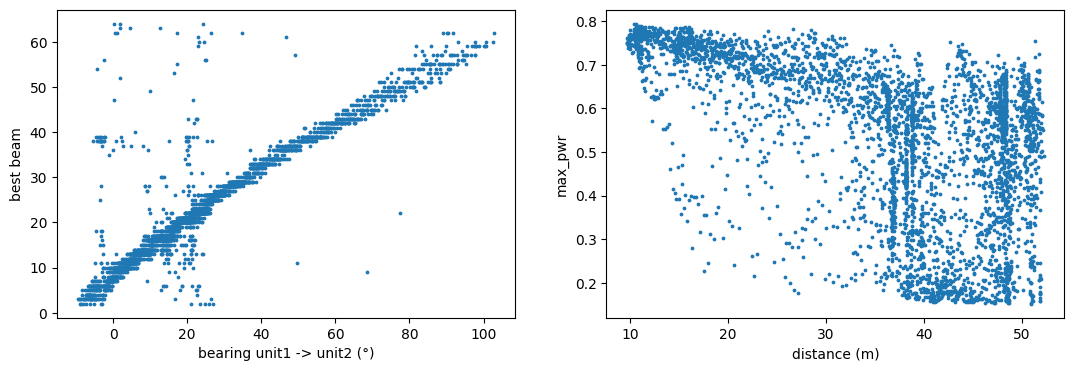

In [ ]:
df[["dist_m", "bearing_deg"]] = gps2.loc[df.index, ["dist_m", "bearing_deg"]]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(df["bearing_deg"], df["unit1_beam"], s=3)
ax[0].set_xlabel("bearing unit1 -> unit2 (°)"); ax[0].set_ylabel("best beam")
ax[1].scatter(df["dist_m"], df["unit1_max_pwr"], s=3)
ax[1].set_xlabel("distance (m)"); ax[1].set_ylabel("max_pwr")
plt.show()

In [ ]:
df[["unit1_beam", "bearing_deg", "dist_m", "unit1_max_pwr"]].corr(method="spearman").round(2)

,unit1_beam,bearing_deg,dist_m,unit1_max_pwr
unit1_beam,1.00,0.91,-0.86,0.49
bearing_deg,0.91,1.00,-0.93,0.51
dist_m,-0.86,-0.93,1.00,-0.56
unit1_max_pwr,0.49,0.51,-0.56,1.00


Vitesse de unit2 fel wa9t (couleur = position interpolée wala non; les NaN ma yodhhrouch).

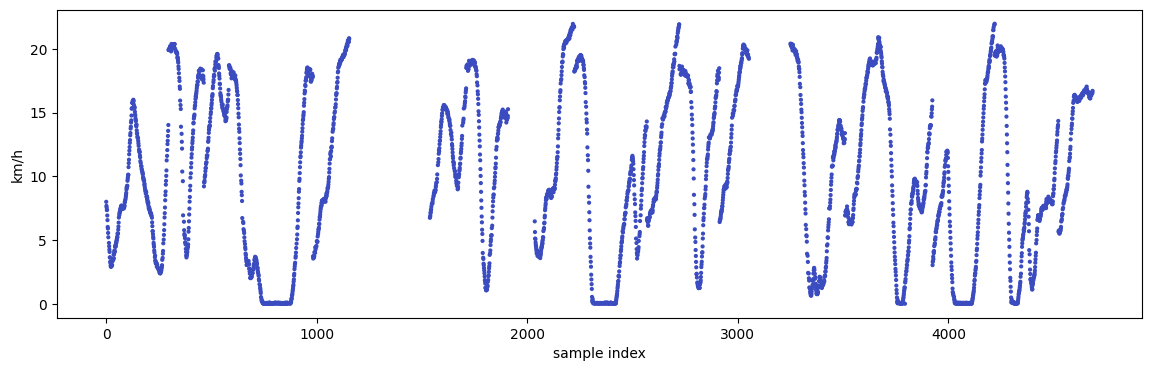

In [ ]:
plt.figure(figsize=(14, 4))
plt.scatter(df.index, df["unit2_spd_over_grnd_kmph"], c=df["unit2_interpolated_position"], cmap="coolwarm", s=4)
plt.xlabel("sample index"); plt.ylabel("km/h")
plt.show()

### 3.7 Un sample, toutes les modalités

Trah nchoufou kolchey maa baadhou.

Fonction `show_sample(i)`: pour un index `i`, tjib camera + LiDAR (vue de haut) + mmWave (el beam el mkhtar b rouge) + radar (range-Doppler w range-angle) + position GPS relative.

In [ ]:
def radar_maps(r):
    # r: (4, 256, 250) complex -> range-Doppler (256, 250) w range-angle (256, 64), en dB
    rfft = np.fft.fft(r, axis=1)
    rd = np.abs(np.fft.fftshift(np.fft.fft(rfft, axis=2), axes=2)).mean(axis=0)
    ra = np.fft.fftshift(np.abs(np.fft.fft(rfft, n=64, axis=0)).mean(axis=2), axes=0).T
    return 20 * np.log10(rd + 1e-6), 20 * np.log10(ra + 1e-6)

In [ ]:
def show_sample(i):
    row = df.loc[i]
    img = plt.imread(main_dir / row["unit1_rgb"])
    pts = load_lidar(main_dir / row["unit1_lidar"])
    power = np.loadtxt(main_dir / row["unit1_pwr_60ghz"])
    rd, ra = radar_maps(np.load(main_dir / row["unit1_radar"]))
    g = gps2.loc[i]

    fig, ax = plt.subplots(2, 3, figsize=(18, 10))
    ax[0, 0].imshow(img); ax[0, 0].axis("off"); ax[0, 0].set_title("Camera")

    ax[0, 1].scatter(pts[:, 0], pts[:, 1], c=pts[:, 2], s=1, cmap="viridis")
    ax[0, 1].set_aspect("equal"); ax[0, 1].set_title(f"LiDAR, vue de haut ({len(pts)} pts, couleur = z)")

    ax[0, 2].plot(range(1, len(power) + 1), power)
    ax[0, 2].axvline(row["unit1_beam"], color="r", ls="--", label=f"beam {row['unit1_beam']}")
    ax[0, 2].set_xlabel("beam"); ax[0, 2].set_title("mmWave power"); ax[0, 2].legend()

    ax[1, 0].imshow(rd, aspect="auto", origin="lower", cmap="viridis")
    ax[1, 0].set_title("Radar range-Doppler (dB)"); ax[1, 0].set_xlabel("Doppler bin"); ax[1, 0].set_ylabel("Range bin")

    ax[1, 1].imshow(ra, aspect="auto", origin="lower", cmap="viridis")
    ax[1, 1].set_title("Radar range-angle (dB)"); ax[1, 1].set_xlabel("Angle bin"); ax[1, 1].set_ylabel("Range bin")

    ax[1, 2].scatter(gps2["x_m"], gps2["y_m"], s=2, c="lightgray")
    ax[1, 2].plot([0, g["x_m"]], [0, g["y_m"]], "k--", lw=1)
    ax[1, 2].scatter(0, 0, c="red", marker="*", s=250, label="unit1")
    ax[1, 2].scatter(g["x_m"], g["y_m"], c="blue", s=60, label="unit2")
    ax[1, 2].set_aspect("equal"); ax[1, 2].legend()
    ax[1, 2].set_title(f"GPS: dist={g['dist_m']:.0f} m, bearing={g['bearing_deg']:.0f}°")

    fig.suptitle(f"sample {i} | seq {row['seq_index']} | t={row['time_stamp']} | beam={row['unit1_beam']} | "
                 f"max_pwr={row['unit1_max_pwr']:.3f} | vitesse={row['unit2_spd_over_grnd_kmph']:.1f} km/h", fontsize=14)
    plt.tight_layout()
    plt.show()

Beam el sghir w el kbir (el 2 extrêmes), bech nchoufou kifech yetbadlou el modalités:

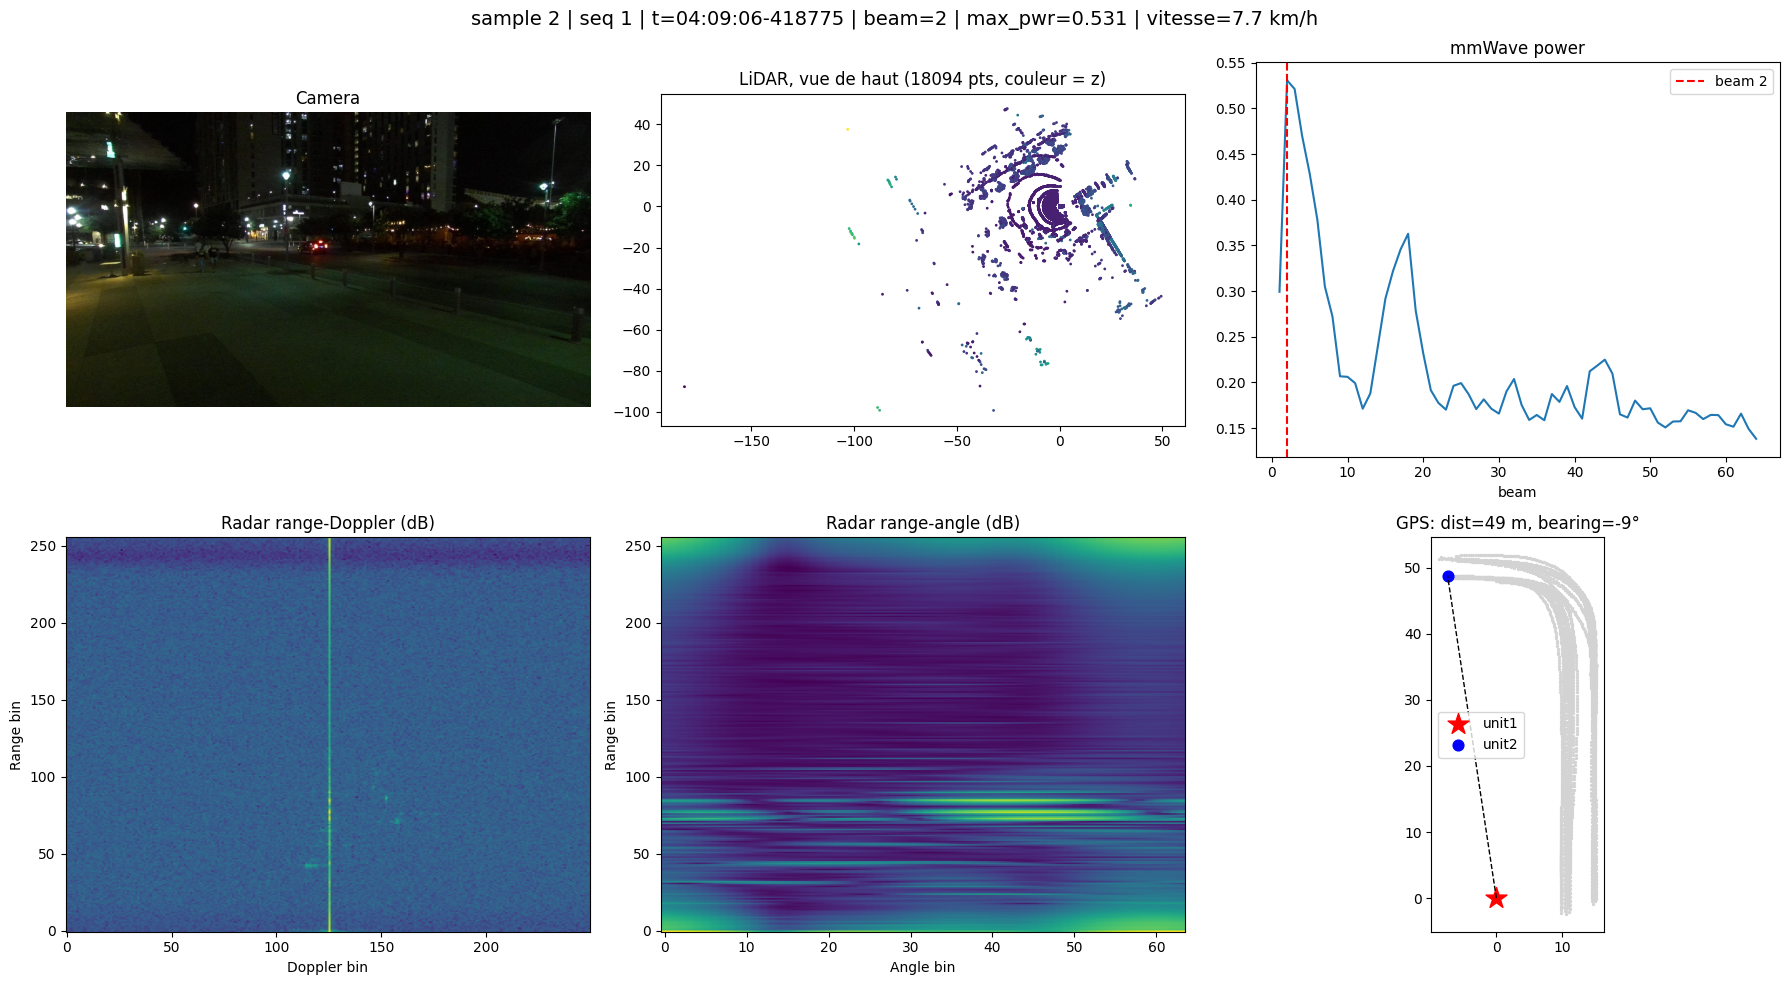

In [ ]:
show_sample(df["unit1_beam"].idxmin())

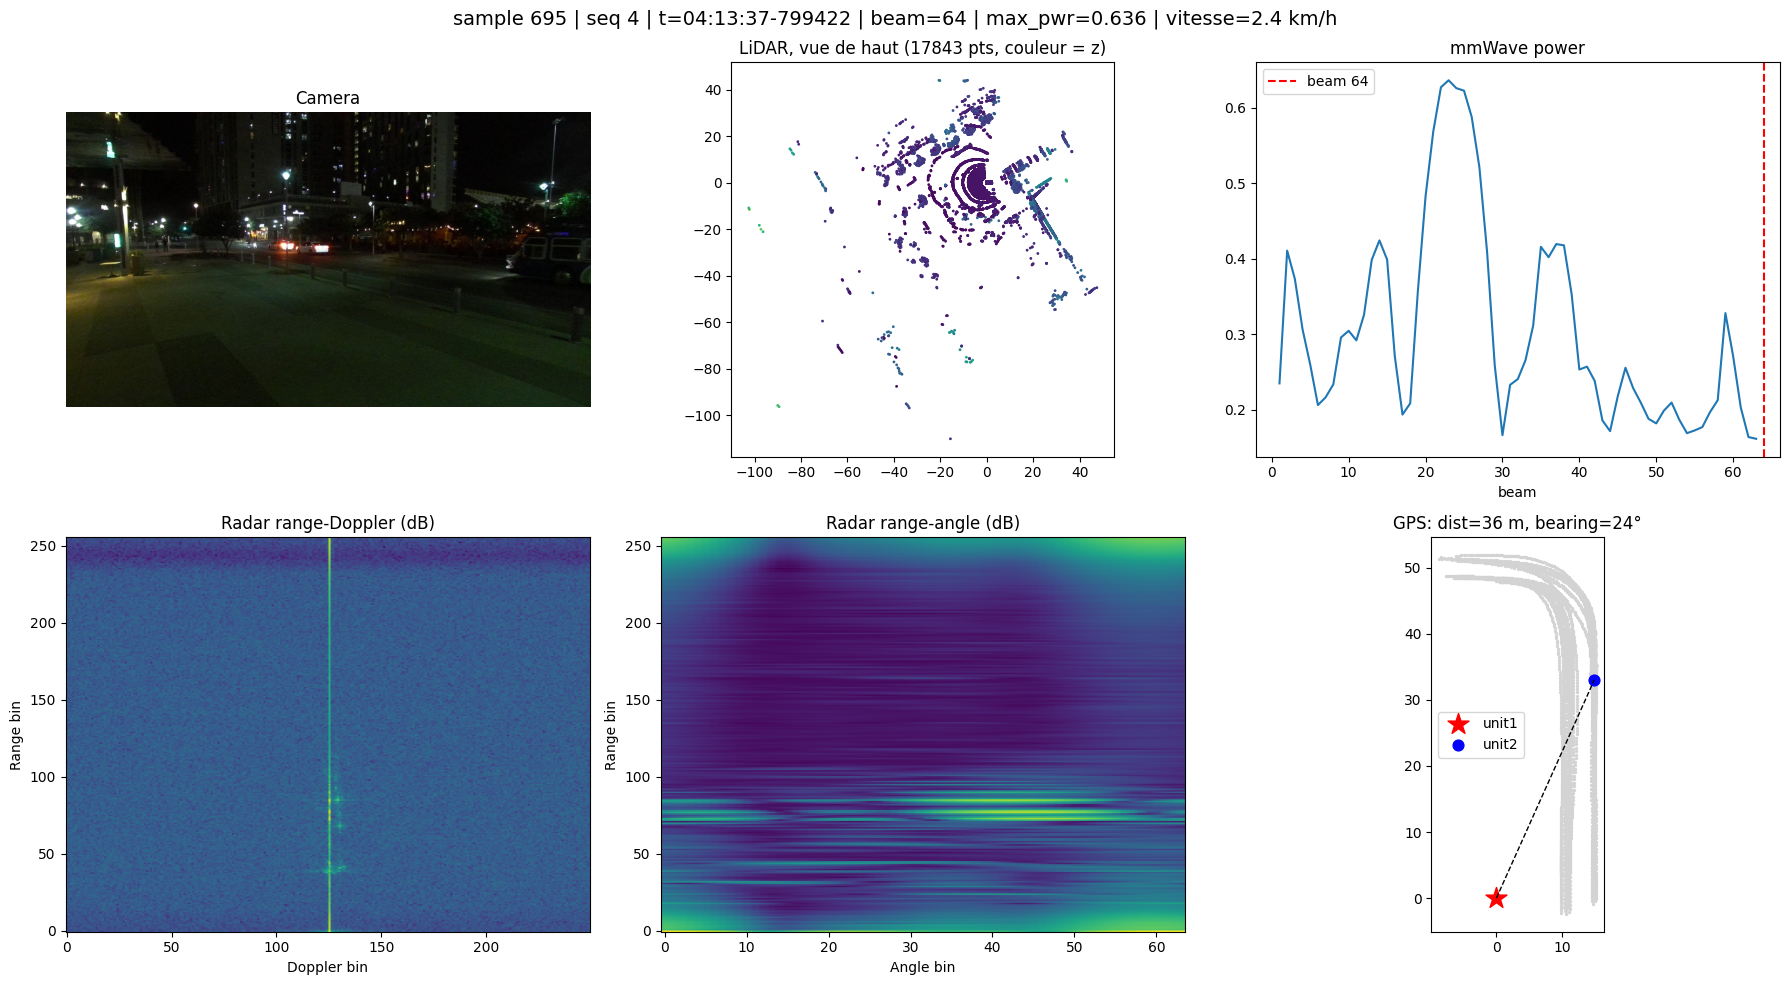

In [ ]:
show_sample(df["unit1_beam"].idxmax())